## Forecasting and Regime Results

**Load all existing forecasts on the common test period**

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').exists())
sys.path.insert(0, str(PROJECT_ROOT))

from modelling.evaluation import load_saved_comparison, verify_saved_result_parity

RESULTS = PROJECT_ROOT / 'data' / 'processed' / 'model_results'
forecasts, metrics = load_saved_comparison(RESULTS)

In [2]:
display(metrics)
print(f"Common test period: {forecasts['Date'].min().date()} to {forecasts['Date'].max().date()}")
print(f"Common test observations: {len(forecasts)}")

,model,rmse,mae,mean_error_actual_minus_forecast
0,AR(1),0.265153,0.195604,0.067525
1,ARX + sentiment,0.266704,0.196726,0.065917
2,AR-HMM,0.269457,0.196073,0.074375
3,LASSO inflation + sentiment,0.286343,0.206879,0.103771
4,LASSO inflation only,0.291463,0.209857,0.109276
5,AR-HMM + sentiment,0.300815,0.213690,0.088730
6,HMM,0.331266,0.235046,0.128187


Common test period: 2017-01-01 to 2023-12-01
Common test observations: 84


<Axes: title={'center': 'Existing model forecasts: common 2017–2023 test period'}, xlabel='Date', ylabel='Monthly inflation (%)'>

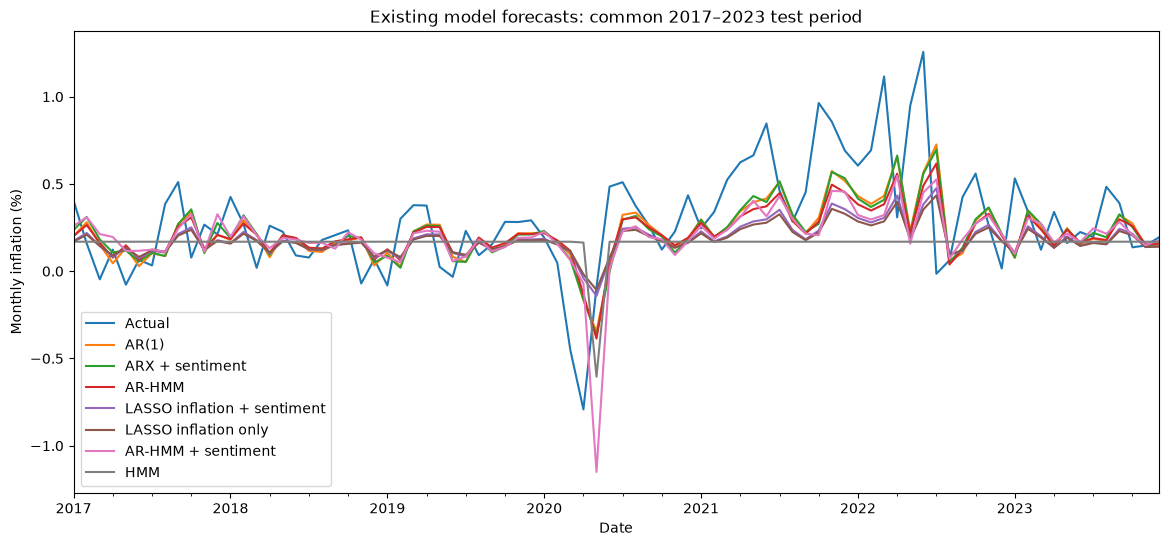

In [3]:
model_columns = metrics['model'].tolist()
forecasts.set_index('Date')[['Actual', *model_columns]].plot(
    figsize=(14, 6),
    title='Existing model forecasts: common 2017–2023 test period',
    ylabel='Monthly inflation (%)',
)

In [4]:
parity = verify_saved_result_parity(RESULTS)
display(parity)
assert parity['matches_saved_result'].all(), 'Saved result parity failed.'

,model,maximum_absolute_difference,matches_saved_result
0,AR(1),1.387779e-17,True
1,AR-HMM,1.387779e-17,True
2,AR-HMM + sentiment,2.775558e-17,True
3,ARX + sentiment,5.551115e-17,True
4,HMM,5.551115e-17,True
5,LASSO inflation + sentiment,5.551115e-17,True
6,LASSO inflation only,4.163336e-17,True


**Existing regime-model results**

In [5]:
hmm = json.loads((RESULTS / 'hmm_metrics.json').read_text(encoding='utf-8'))
arhmm = json.loads((RESULTS / 'ar_hmm_metrics.json').read_text(encoding='utf-8'))

regime_metrics = pd.DataFrame([
    {'model': 'HMM', **hmm['metrics']},
    {'model': 'AR-HMM', **arhmm['variants']['inflation_only']['metrics']},
    {'model': 'AR-HMM + sentiment', **arhmm['variants']['with_sentiment']['metrics']},
])
display(regime_metrics.sort_values('rmse'))
display(pd.DataFrame({'HMM state mean': hmm['parameters']['state_means']}))

,model,rmse,mae,mean_error_actual_minus_forecast
1,AR-HMM,0.269457,0.196073,0.074375
2,AR-HMM + sentiment,0.300815,0.213690,0.088730
0,HMM,0.331266,0.235046,0.128187


,HMM state mean
0,0.181368
1,-1.131495


<Axes: title={'center': 'Existing AR-HMM forecasts'}, xlabel='Date', ylabel='Monthly inflation (%)'>

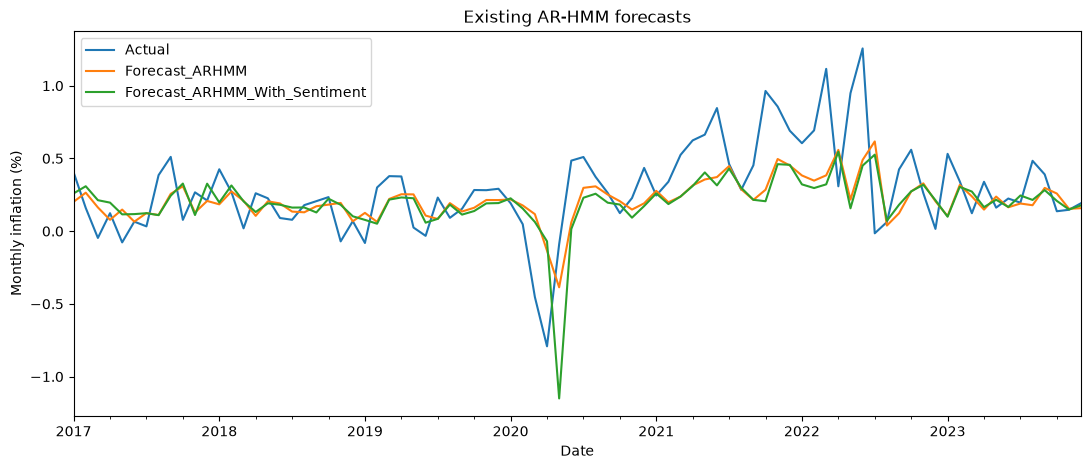

In [6]:
regime_forecasts = pd.read_csv(RESULTS / 'ar_hmm_forecasts.csv', parse_dates=['Date']).set_index('Date')
regime_forecasts[['Actual', 'Forecast_ARHMM', 'Forecast_ARHMM_With_Sentiment']].plot(
    figsize=(13, 5),
    title='Existing AR-HMM forecasts',
    ylabel='Monthly inflation (%)',
)